# Tratamiento de imagen con OpenCV — diagnóstico y corrección justificada
**Especialización en Inteligencia Artificial · Semana 8** — Autor: Jahir Avila

Flujo: **(1)** conjunto de 5 imágenes del mismo objeto bajo condiciones distintas → **(2)** diagnóstico
(resolución, canales, brillo, contraste, nitidez, ruido, bordes, formato y tamaño) → **(3)** tabla comparativa y
detección de problemas → **(4)** tratamiento de la imagen problemática elegida → **(5)** evaluación antes/después.

> **Imágenes.** Si la carpeta `imagenes/` no tiene fotos, el notebook genera un conjunto de **prueba** simulado a partir
> de `skimage.data.coffee()` (dominio público). Para la versión final, suba sus 5 fotos con los mismos nombres
> (`1_referencia`, `2_baja_iluminacion`, `3_desenfoque_movimiento`, `4_fondo_complejo`, `5_perspectiva`; .jpg o .png)
> y ejecute *Entorno de ejecución → Ejecutar todo*.

In [1]:
# 0. Preparar entorno (Colab clona el repositorio; en local usa la carpeta actual)
import os, sys
REPO_URL = "https://github.com/jahirravila/tratamiento-imagen-opencv"  # <- ajustar si el repo tiene otro nombre
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
if not os.path.isdir("src"):
    os.system(f"git clone -q {REPO_URL} repo && echo clonado")
    os.chdir("repo")
sys.path.insert(0, "src")
print("Directorio de trabajo:", os.getcwd())

Directorio de trabajo: /home/claude/tratamiento-imagen-opencv


In [2]:
import glob, cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
import generar_imagenes_prueba as gen, diagnostico as dg, tratamiento as tr, figuras as fg
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
print("OpenCV", cv2.__version__)

if len(glob.glob("imagenes/*.*")) < 5:
    gen.main("imagenes")          # conjunto de prueba (reemplazar por fotos propias)
RUTAS = sorted(glob.glob("imagenes/*.*")); RUTAS

OpenCV 5.0.0


['imagenes/1_referencia.jpg',
 'imagenes/2_baja_iluminacion.jpg',
 'imagenes/3_desenfoque_movimiento.jpg',
 'imagenes/4_fondo_complejo.jpg',
 'imagenes/5_perspectiva.png']

## 1. Conjunto de imágenes y condiciones de captura
| # | Condición | Cómo se produjo (conjunto de prueba) |
|---|---|---|
| 1 | Referencia | Imagen original, buena exposición y foco (JPEG q95) |
| 2 | Baja iluminación | Luz ×0.30, gamma 1.3 y ruido gaussiano σ=6 (sensor con ISO alto) |
| 3 | Desenfoque / movimiento | Convolución con kernel lineal de 25 px a 20° |
| 4 | Fondo complejo | Objeto segmentado con GrabCut sobre un fondo con formas, texto y rayas |
| 5 | Perspectiva | Homografía (cámara inclinada y rotada) + menor resolución, guardada en PNG |

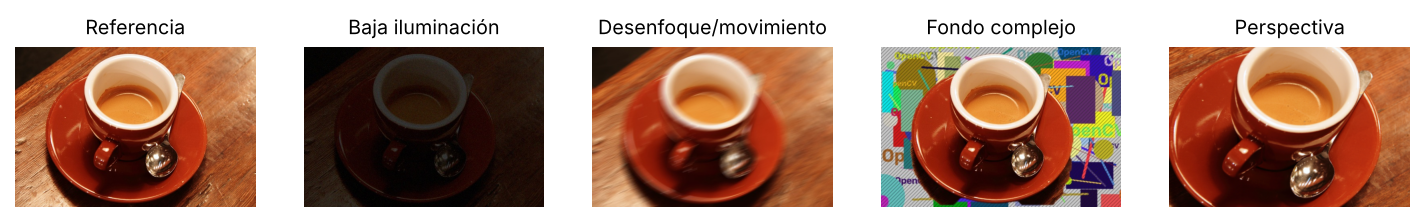

In [3]:
fg.conjunto(RUTAS, "resultados"); display(Image("resultados/fig_conjunto.png"))

## 2. Diagnóstico
Métricas sin referencia calculadas en `src/diagnostico.py`:
* **Brillo**: media del gris, % de píxeles < 30 (sombras) y > 245 (saturados).
* **Contraste**: desviación estándar (RMS) y rango dinámico p2–p98.
* **Nitidez**: varianza del Laplaciano y Tenengrad (magnitud media del gradiente de Sobel).
* **Ruido**: σ por el método de Immerkær; *ruido relativo* = σ / brillo (inverso de la SNR).
* **Bordes**: % de píxeles de borde con Canny (umbrales automáticos por la mediana).
* **Archivo**: formato, tamaño en KB y bits por píxel tras la compresión; resolución y canales.

In [4]:
df = dg.main("imagenes", "resultados")
df.set_index("imagen").T

imagen,1_referencia.jpg,2_baja_iluminacion.jpg,3_desenfoque_movimiento.jpg,4_fondo_complejo.jpg,5_perspectiva.png
formato,JPG,JPG,JPG,JPG,PNG
resolucion,600x400,600x400,600x400,600x400,480x320
megapixeles,0.24,0.24,0.24,0.24,0.154
canales,3,3,3,3,3
tamano_kb,102.3,61.6,38.1,86.8,230.0
bits_por_pixel,3.49,2.1,1.3,2.96,12.27
brillo_media,103.6,18.2,103.7,110.3,98.6
pct_oscuros,15.2,83.3,12.8,14.1,15.5
pct_saturados,0.6,0.0,0.0,0.6,0.6
contraste_rms,58.1,11.9,53.3,65.2,59.1


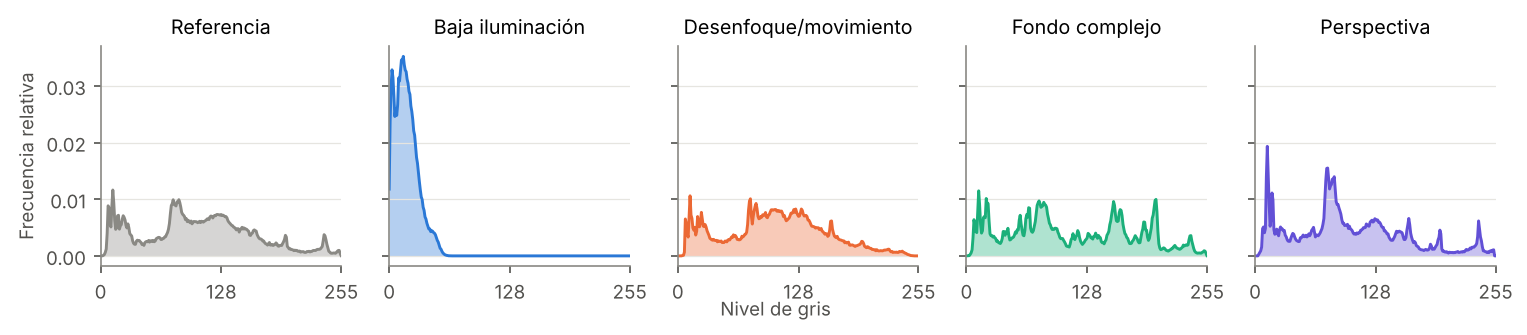

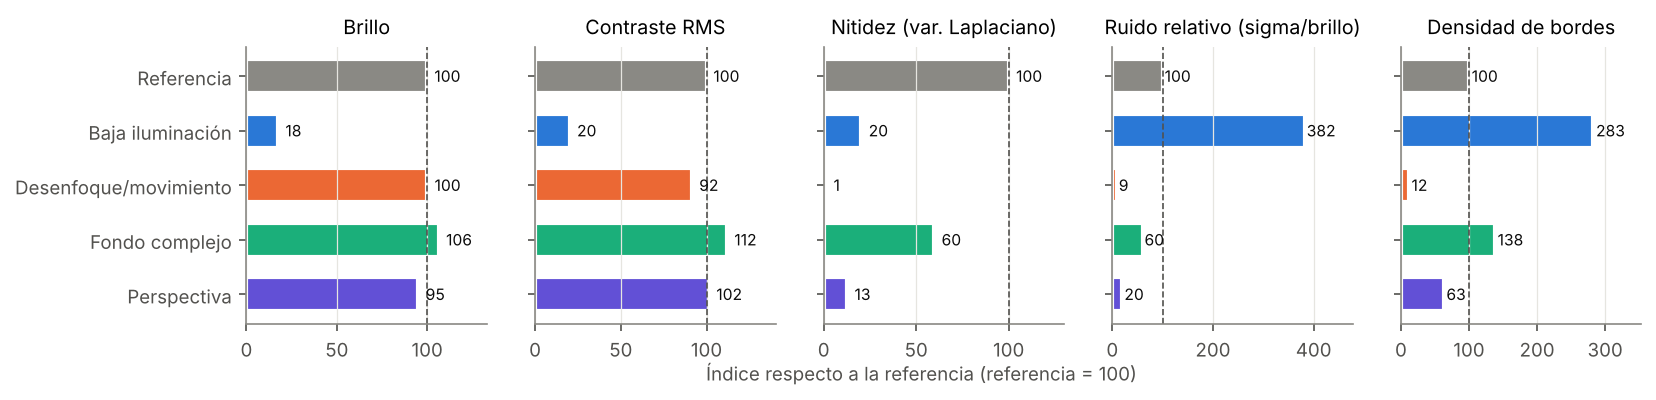

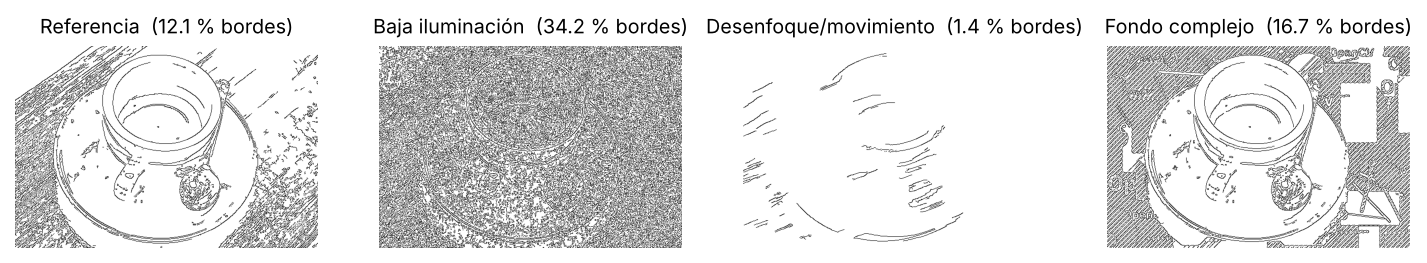

In [5]:
fg.histogramas(RUTAS, "resultados"); fg.metricas_indexadas(df, "resultados"); fg.bordes(RUTAS, "resultados")
for f in ["fig_histogramas.png", "fig_metricas.png", "fig_bordes.png"]:
    display(Image(f"resultados/{f}"))

### Lectura del diagnóstico
* **Baja iluminación**: brillo ≈ 18 % de la referencia, >80 % de píxeles en sombra y histograma comprimido en 0–60.
  El ruido relativo es ~4× el de la referencia y Canny marca ~34 % de píxeles como borde: son **bordes falsos producidos por el ruido**.
* **Desenfoque**: brillo y contraste casi intactos, pero la varianza del Laplaciano cae al ~1 %; el problema es solo de altas frecuencias.
* **Fondo complejo**: buena exposición, pero más bordes que la referencia; un detector de contornos o un clasificador recibirá distractores.
* **Perspectiva**: menor resolución y pérdida de detalle por el remuestreo de la homografía; el PNG pesa ~2× más que el JPEG de mayor resolución (compresión sin pérdida).

**Problema seleccionado: baja iluminación**, porque combina tres defectos medibles (subexposición, bajo contraste y baja SNR) y es el que más degrada la percepción: casi todas las métricas se alejan de la referencia.

## 3. Tratamiento de la imagen con baja iluminación
Se comparan técnicas clásicas (A–C) con una cadena propuesta (D) y una ablación del orden (E). Ver `src/tratamiento.py`.

In [6]:
res = tr.main("imagenes/2_baja_iluminacion.jpg", "imagenes/1_referencia.jpg", "resultados")
res

,tecnica,brillo_media,contraste_rms,rango_dinamico_p2_p98,entropia_bits,nitidez_lap_var,ruido_relativo,densidad_bordes_pct,croma_medio,PSNR_dB,SSIM
0,Original (baja luz),18.2,11.9,47,5.46,319.6,0.172,34.2,8.3,8.07,0.242
1,A. Gamma automatica,98.0,30.6,151,5.88,2666.2,0.090,17.4,8.3,14.14,0.420
2,B. Ecualizacion global,129.2,73.7,244,5.45,13601.8,0.156,31.8,7.5,12.84,0.298
3,"C. CLAHE (L, clip 3)",44.1,28.6,118,6.50,2827.0,0.210,35.6,8.4,10.50,0.394
4,D. Propuesto: gamma+NLM+croma+CLAHE,105.2,36.0,177,6.97,1711.9,0.043,10.4,20.4,16.20,0.515
5,E. Ablacion: NLM antes de gamma,98.8,38.2,174,7.04,5345.6,0.132,31.2,8.5,14.53,0.389
6,Referencia,103.6,58.1,228,7.66,1572.3,0.045,12.1,42.9,NaN,NaN


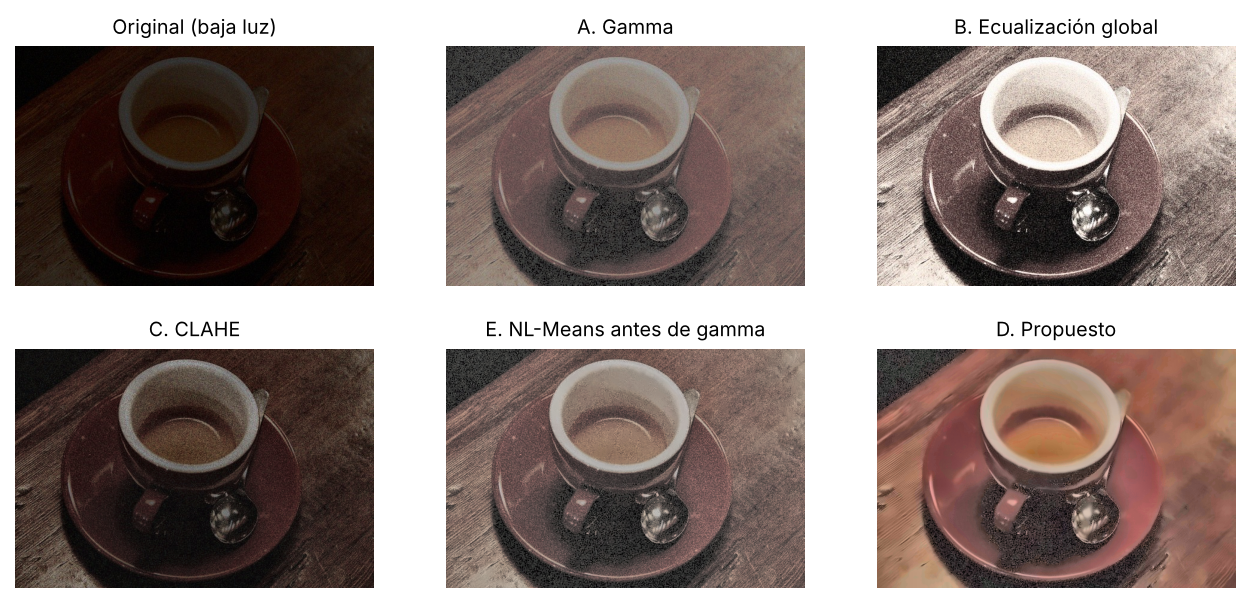

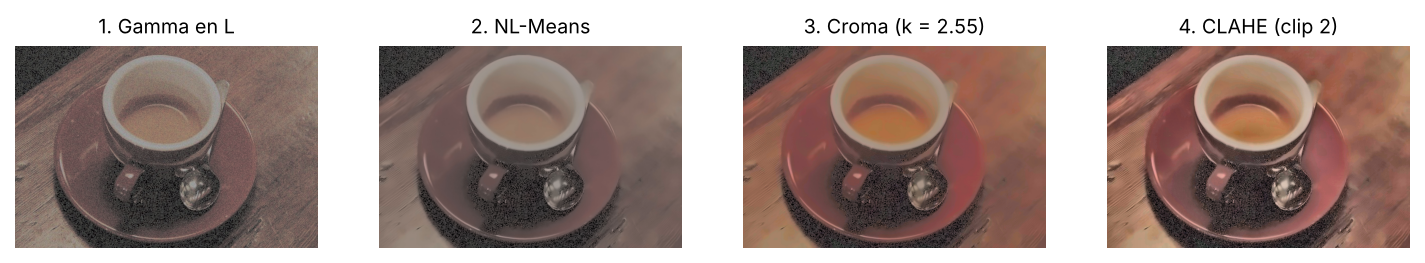

In [7]:
fg.tecnicas("resultados", "resultados"); fg.pasos("imagenes", "resultados")
for f in ["fig_tecnicas.png", "fig_pasos.png"]:
    display(Image(f"resultados/{f}"))

## 4. Antes / después

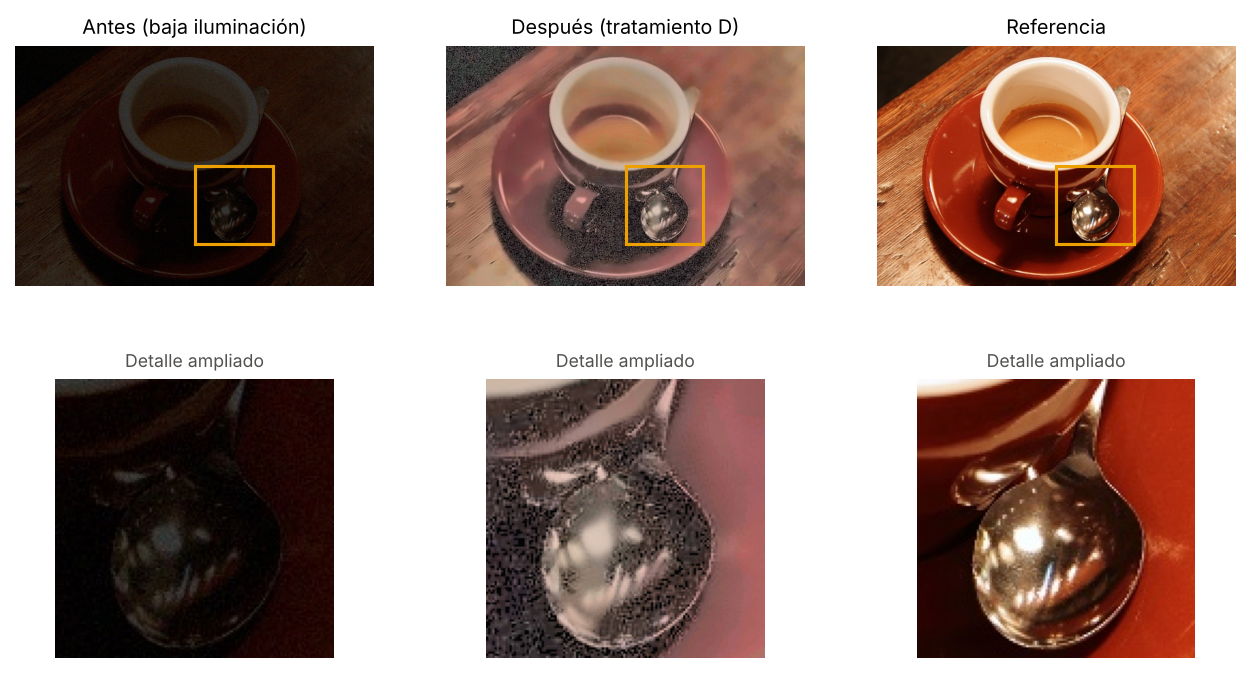

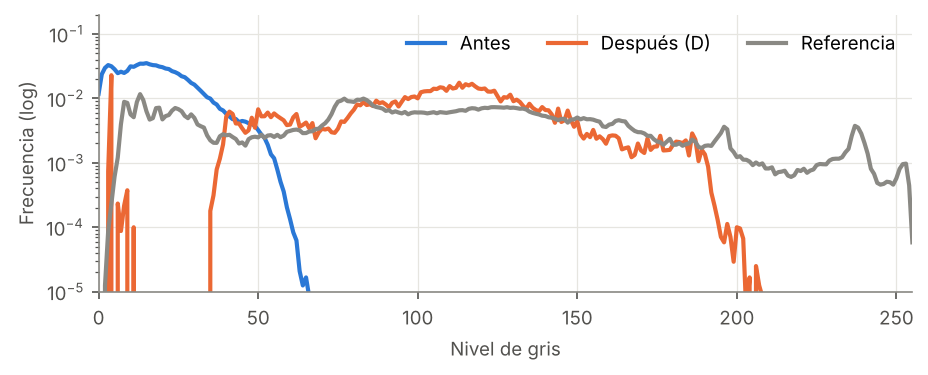

tecnica,Original (baja luz),D. Propuesto: gamma+NLM+croma+CLAHE,Referencia
brillo_media,18.200,105.200,103.600
contraste_rms,11.900,36.000,58.100
rango_dinamico_p2_p98,47.000,177.000,228.000
entropia_bits,5.460,6.970,7.660
nitidez_lap_var,319.600,1711.900,1572.300
ruido_relativo,0.172,0.043,0.045
densidad_bordes_pct,34.200,10.400,12.100
croma_medio,8.300,20.400,42.900
PSNR_dB,8.070,16.200,NaN
SSIM,0.242,0.515,NaN


In [8]:
fg.antes_despues("imagenes", "resultados", "resultados")
display(Image("resultados/fig_antes_despues.png")); display(Image("resultados/fig_hist_antes_despues.png"))
cols = ["brillo_media","contraste_rms","rango_dinamico_p2_p98","entropia_bits","nitidez_lap_var",
        "ruido_relativo","densidad_bordes_pct","croma_medio","PSNR_dB","SSIM"]
res.set_index("tecnica").loc[["Original (baja luz)", "D. Propuesto: gamma+NLM+croma+CLAHE", "Referencia"], cols].T

## 5. Análisis y conclusiones
* **A (gamma)** recupera el brillo pero amplifica el ruido y deja el color lavado.
* **B (ecualización global)** maximiza el contraste, pero sobrecorrige: ruido alto, bordes falsos y la peor SSIM de las técnicas de realce.
* **C (CLAHE)** realza el contraste local, pero sin corregir primero el brillo amplifica el ruido de las sombras (ruido relativo más alto de todas).
* **D (propuesto)** es la mejor en PSNR y SSIM y deja ruido relativo y densidad de bordes al nivel de la referencia.
* **E (ablación)**: si se elimina el ruido *antes* de aclarar, el ruido queda por debajo del umbral del filtro y reaparece al aplicar la gamma → el orden importa.

**Limitaciones**: el contraste y el croma siguen por debajo de la referencia; las sombras profundas perdieron información al cuantizarse con pocos niveles y NL-Means suaviza texturas finas (veta de la madera).
PSNR/SSIM solo son válidos aquí porque las vistas están alineadas; con fotos reales se usan las métricas sin referencia.

**Recomendación**: la mejor corrección es preventiva (más luz, trípode, menor ISO, formato RAW).